In [1]:
from pathlib import Path
from datetime import datetime


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["savefig.dpi"] = 1200
from scipy import stats
from IPython.display import display
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator
import zipfile

RUN_DIR = "results/run_20261007_221055"

FIGURE_CSV_ROOT = Path(RUN_DIR).resolve() / "figure_csv"
FIGURE_CSV_ROOT.mkdir(parents=True, exist_ok=True)
_stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
FIGURE_CSV_DIR = FIGURE_CSV_ROOT / _stamp
_suffix = 1
while FIGURE_CSV_DIR.exists():
    FIGURE_CSV_DIR = FIGURE_CSV_ROOT / f"{_stamp}_{_suffix}"
    _suffix += 1
FIGURE_CSV_DIR.mkdir()
print("Figures / tables output:", FIGURE_CSV_DIR)

MAIN_CONDITION = "degradation_degw_1_vdevw_0p2_p_0p8_rho_0p4_CA"
SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
MA_W = 5   
TH = 0.9       
ALGOS = {
    "CAHG-MASAC": ("CAHG-MASAC [Ours]", "sienna",  "royalblue",  "*"),
    "CA-MASAC":   ("CA-MASAC",          "green",   "darkorange", None),
    "MASAC":      ("MASAC",             "dimgray", "sienna",     None),
    "CAHG-MATD3": ("CAHG-MATD3",        "orange",  "lightcoral", "*"),
    "CA-MATD3":   ("CA-MATD3",          "skyblue", "skyblue",    None),
    "MATD3":      ("MATD3",             "orchid",  "orchid",     None),
}
MODES = {"V2G": (True,  "VPP Event Episode", 1),     
         "V2H": (False, "Non VPP Episode",   2)}

def ci95(x):
    x = np.asarray(x, float); n = len(x)
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return x.mean(), x.mean() - h, x.mean() + h

def load_seed(s):
    for f in sorted(Path(f"{RUN_DIR}/seed{s}").glob(f"all_daily_rewards_seed{s}_c*.csv")):
        if pd.read_csv(f, nrows=1, encoding="utf-8-sig").condition[0] == MAIN_CONDITION:
            df = pd.read_csv(f, encoding="utf-8-sig")
            return df[df.phase == "train"].sort_values("day_idx")
    raise FileNotFoundError(f"seed{s}: {MAIN_CONDITION}")


dfs = [load_seed(s) for s in SEEDS]
R = {mode: {a: np.array([d[(d.algorithm == a) & (d.vpp_request == vpp)].reward.values for d in dfs])
            for a in ALGOS}
     for mode, (vpp, _, _) in MODES.items()}

def show(tab):
    display(tab.style.format(precision=3)
               .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
               .set_properties(**{"text-align": "center"})
               .apply(lambda r: ["font-weight: bold; border-top: 2px solid black" if r.name == "Mean"
                                 else "font-weight: bold" if r.name == "SD" else ""
                                 for _ in r], axis=1))

def show(tab):
    display(tab.style.format(precision=3)
               .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
               .set_properties(**{"text-align": "center"})
               .apply(lambda r: ["font-weight: bold; border-top: 2px solid black" if r.name == "Mean"
                                 else "font-weight: bold" if r.name == "SD" else ""
                                 for _ in r], axis=1))

def plot_curve(mode):
    _, xlabel, col = MODES[mode]
    plt.figure(figsize=(6, 5))
    for a, (label, *colors, marker) in ALGOS.items():
        X = R[mode][a]; n = len(X)
        mean = X.mean(0)
        half = stats.t.ppf(0.975, n - 1) * X.std(0, ddof=1) / np.sqrt(n)
        x = np.arange(X.shape[1])
        plt.plot(x, mean, color=colors[col - 1], marker=marker, markersize=6, label=label)
        plt.fill_between(x, mean - half, mean + half, color=colors[col - 1], alpha=0.15, linewidth=0)
    plt.title(f"{mode} Performance Comparison [10 seeds Average] ± 95% CI", fontweight="bold")
    plt.xlabel(xlabel, fontweight="bold"); plt.ylabel("Reward", fontweight="bold"); plt.grid(True)
    h, l = plt.gca().get_legend_handles_labels()
    order = [0, 3, 1, 4, 2, 5]
    plt.legend([h[i] for i in order], [l[i] for i in order],
               loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=10)
    plt.tight_layout(); plt.savefig(FIGURE_CSV_DIR / f"Figure{8 if mode == 'V2G' else 9:02d}_{mode}_Reward.png", dpi=1200); plt.show()

def show_tables(mode):
    Rmax = max(R[mode][a][:, -30:].mean() for a in ALGOS)
    R0 = np.mean([R[mode][a][:, 0].mean() for a in ALGOS])
    rows = {}

    for a in ALGOS:
        X = R[mode][a]
        m30, lo, hi = ci95(X[:, -30:].mean(1))
        N = (X - R0) / (Rmax - R0)
        A = N.mean(1)
        T = np.array([np.argmax(ma >= TH) + 1 if (ma >= TH).any() else np.nan for ma in (pd.Series(n).rolling(MA_W).mean().values for n in N)])
        valid = T[np.isfinite(T)]
        t90 = f"{valid.mean():.1f} ± {valid.std(ddof=1):.1f}" if len(valid) > 1 else f"{valid[0]:.0f}" if len(valid) else "Not reached"

        rows[a] = {
            "Max reward": X.max(1).mean(),
            "Last 30 mean": m30,
            "95% CI (Last 30)": f"[{lo:.3f}, {hi:.3f}]",
            "T90 (seeds reached)": f"{t90} ({len(valid)}/{len(T)})",
            "AUC": f"{A.mean():.3f} ± {A.std(ddof=1):.3f}"
        }

    print(f"[{mode}] Table 1. Summary by algorithm (10 seeds)")
    T2 = pd.DataFrame(rows).T
    show(T2)
    T2.to_csv(FIGURE_CSV_DIR / f"Table2_{mode}_summary.csv", encoding="utf-8-sig")

    cols = pd.MultiIndex.from_product([ALGOS, ["Max reward", "Last 30 mean"]])
    T3 = pd.DataFrame({a: R[mode][a][:, -30:].mean(1) for a in ALGOS}, index=[f"Seed {s}" for s in SEEDS])
    seeds = T3.copy()
    T3.loc["Mean ± SD"] = [f"{seeds[a].mean():.3f} ± {seeds[a].std(ddof=1):.3f}" for a in ALGOS]

    show(T3)
    T3.to_csv(FIGURE_CSV_DIR / f"Table3_{mode}_per_seed.csv", encoding="utf-8-sig")


def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for k, i in enumerate(order):
        run = max(run, (len(p) - k) * p[i]); adj[i] = min(run, 1.0)
    return adj

def wilcoxon_p(x, y):
    return 1.0 if np.allclose(x, y) else stats.wilcoxon(x, y).pvalue

Figures / tables output: C:\Users\SOMAYS\CAHG\results\run_20261007_221055\figure_csv\20261011_223837


# Figure 8. V2G(+V2H) Event Reward

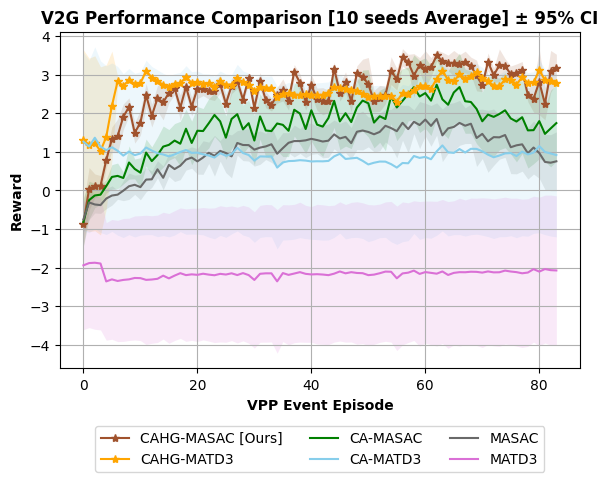

In [2]:
plot_curve("V2G")

# Table 2. V2G(+V2H) Performances

In [3]:
show_tables("V2G")

[V2G] Table 1. Summary by algorithm (10 seeds)


,Max reward,Last 30 mean,95% CI (Last 30),T90 (seeds reached),AUC
CAHG-MASAC,3.787,3.077,"[2.977, 3.177]",34.3 ± 11.2 (10/10),0.834 ± 0.022
CA-MASAC,3.133,2.118,"[1.315, 2.921]",52.4 ± 8.6 (7/10),0.571 ± 0.238
MASAC,2.143,1.404,"[0.880, 1.927]",Not reached (0/10),0.394 ± 0.140
CAHG-MATD3,3.367,2.792,"[2.768, 2.816]",7.1 ± 3.2 (10/10),0.864 ± 0.062
CA-MATD3,1.535,0.928,"[-1.197, 3.052]",5.0 ± 0.0 (7/10),0.359 ± 0.873
MATD3,-1.399,-2.121,"[-4.009, -0.233]",56.0 ± 9.9 (2/10),-0.550 ± 0.732


,CAHG-MASAC,CA-MASAC,MASAC,CAHG-MATD3,CA-MATD3,MATD3
Seed 0,3.189,2.929,1.289,2.806,2.769,2.865
Seed 1,3.059,0.681,1.151,2.776,-3.378,-3.378
Seed 2,2.826,0.637,2.209,2.846,-3.384,-3.384
Seed 3,3.286,3.426,1.928,2.793,-3.365,-3.365
Seed 4,3.119,3.175,1.408,2.801,2.791,2.909
Seed 5,2.974,3.293,2.058,2.794,2.790,-3.408
Seed 6,2.971,2.585,1.857,2.809,2.795,-3.362
Seed 7,2.982,1.847,-0.082,2.714,2.710,-3.342
Seed 8,3.148,0.758,1.743,2.793,2.802,-3.378
Seed 9,3.216,1.848,0.475,2.786,2.748,-3.367


# Figure 9. V2H Event Reward

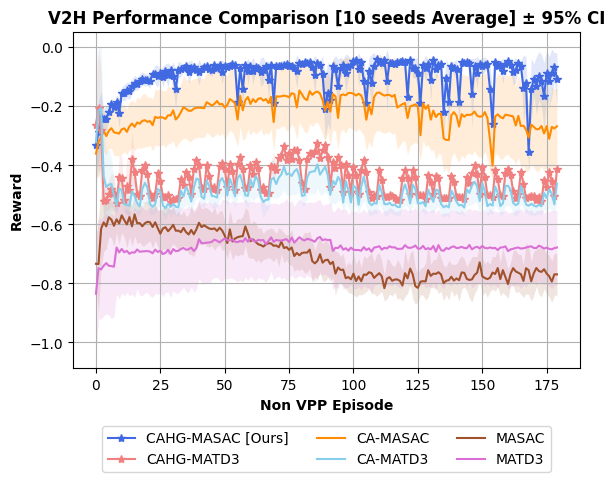

In [4]:
plot_curve("V2H")

# Table 3. V2H Performances

In [5]:
show_tables("V2H")

[V2H] Table 1. Summary by algorithm (10 seeds)


,Max reward,Last 30 mean,95% CI (Last 30),T90 (seeds reached),AUC
CAHG-MASAC,-0.034,-0.104,"[-0.135, -0.073]",16.6 ± 2.4 (10/10),1.019 ± 0.026
CA-MASAC,-0.123,-0.264,"[-0.386, -0.142]",38.1 ± 12.2 (7/10),0.687 ± 0.368
MASAC,-0.476,-0.770,"[-0.822, -0.717]",Not reached (0/10),-0.627 ± 0.157
CAHG-MATD3,-0.051,-0.472,"[-0.474, -0.471]",Not reached (0/10),0.069 ± 0.014
CA-MATD3,-0.168,-0.510,"[-0.553, -0.467]",5 (1/10),-0.036 ± 0.188
MATD3,-0.590,-0.680,"[-0.805, -0.555]",Not reached (0/10),-0.550 ± 0.492


,CAHG-MASAC,CA-MASAC,MASAC,CAHG-MATD3,CA-MATD3,MATD3
Seed 0,-0.094,-0.077,-0.651,-0.477,-0.480,-1.013
Seed 1,-0.086,-0.425,-0.861,-0.473,-0.598,-0.598
Seed 2,-0.224,-0.418,-0.786,-0.473,-0.592,-0.592
Seed 3,-0.082,-0.063,-0.734,-0.475,-0.599,-0.599
Seed 4,-0.090,-0.085,-0.742,-0.469,-0.472,-1.011
Seed 5,-0.099,-0.068,-0.830,-0.472,-0.471,-0.595
Seed 6,-0.089,-0.267,-0.732,-0.472,-0.475,-0.598
Seed 7,-0.084,-0.411,-0.847,-0.470,-0.471,-0.596
Seed 8,-0.105,-0.424,-0.676,-0.472,-0.474,-0.598
Seed 9,-0.088,-0.406,-0.837,-0.470,-0.469,-0.599


# Table 4. Grid Stability Analysis 

In [6]:
STUDIES = [
    ("t2_noV2X", "(i) No V2H & V2G"),
    ("t2_nopen", "(ii) Without penalty"),
    ("t2_ours400", "(iii) CAHG-MASAC (Ours)"),
    ("t2_ours500", "(iv) CAHG-MASAC (Ours)")
]
VPP_ONLY = True
V_MIN, V_MAX = 0.95, 1.05
ALGO_KEY = "hsac"

def load_csv_group(token):
    files = sorted(Path(RUN_DIR).glob(f"seed*/all_{token}*.csv"))
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df = df[df["sweep_type"].str.startswith("t2_")].copy()
    if "algo" in df.columns:
        df = df[df["algo"].str.lower() == ALGO_KEY].copy()
    else:
        df = df[df["algorithm"] == "CAHG-MASAC"].copy()
    return df

daily = load_csv_group("daily_rewards")
grid = load_csv_group("grid_steps")

daily = daily.drop_duplicates(["sweep_type", "seed", "day_idx"], keep="last").copy()
grid = grid.drop_duplicates(["sweep_type", "seed", "t_idx"], keep="last").copy()

for df in (daily, grid):
    df["seed"] = pd.to_numeric(df["seed"]).astype(int)
    df["day_idx"] = pd.to_numeric(df["day_idx"]).astype(int)

for col in ("vpu_min", "vpu_max", "voltage_deviation"):
    grid[col] = pd.to_numeric(grid[col])

daily = daily[daily["phase"].str.lower() == "eval"].copy()

if VPP_ONLY:
    daily = daily[daily["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])].copy()

grid_eval = grid.merge(daily[["sweep_type", "seed", "day_idx"]].drop_duplicates(), on=["sweep_type", "seed", "day_idx"], how="inner")
grid_eval["any_violation"] = ((grid_eval["vpu_min"] < V_MIN) | (grid_eval["vpu_max"] > V_MAX)).astype(int)

rows = []

for study, label in STUDIES:
    d = daily[daily["sweep_type"] == study]
    g = grid_eval[grid_eval["sweep_type"] == study]

    eligible = round(float(d["n_evs"].iloc[0]) * float(d["participation_rate"].iloc[0]))
    total_by_seed = g.groupby("seed")["any_violation"].sum()
    min_by_seed = g.groupby("seed")["vpu_min"].min()
    max_by_seed = g.groupby("seed")["vpu_max"].max()
    deviation_by_seed = g.groupby("seed")["voltage_deviation"].mean()
    violation_by_day = g.groupby(["seed", "day_idx"])["any_violation"].max().reset_index()
    days_rate_by_seed = violation_by_day.groupby("seed")["any_violation"].mean() * 100

    rows.append({
        "Category": label,
        "V2G eligible vehicles": eligible,
        "Voltage violations (mean)": round(total_by_seed.mean(), 1),
        "Days with violation (%)": round(days_rate_by_seed.mean(), 2),
        "mean_deviation (p.u.)": round(deviation_by_seed.mean(), 5),
        "Minimum Vpu": round(min_by_seed.min(), 4),
        "Maximum Vpu": round(max_by_seed.max(), 4)
    })

T4 = pd.DataFrame(rows)
display(T4)
FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
T4.to_csv(FIGURE_CSV_DIR / "Table4_voltage_comparison.csv", index=False, encoding="utf-8-sig")

,Category,V2G eligible vehicles,Voltage violations (mean),Days with violation (%),mean_deviation (p.u.),Minimum Vpu,Maximum Vpu
0,(i) No V2H & V2G,400,18.7,47.78,0.01381,0.9495,1.0516
1,(ii) Without penalty,400,0.2,2.22,0.01117,0.9495,1.0453
2,(iii) CAHG-MASAC (Ours),400,0.1,1.11,0.01092,0.9497,1.0453
3,(iv) CAHG-MASAC (Ours),500,0.0,0.00,0.01007,0.9547,1.0447


# Table 5. Performance Analysis for Evaluation Period

In [7]:
files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)

df = df[(df["condition"] == MAIN_CONDITION) & (df["phase"] == "eval") & (df["algorithm"].isin(ALGOS)) & (df["seed"].isin(SEEDS))].copy()
df = df.drop_duplicates(["condition", "algorithm", "seed", "day_idx", "phase"], keep="last")
df["day_idx"] = pd.to_numeric(df["day_idx"])
df["reward"] = pd.to_numeric(df["reward"])
df["vpp_request"] = df["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

df = df.sort_values("day_idx").groupby(["algorithm", "seed"], group_keys=False).tail(30).copy()
df["Mode"] = np.where(df["vpp_request"], "V2G", "V2H")

rows = {}
for algo in ALGOS:
    rows[algo] = {}
    for mode in ["V2G", "V2H"]:
        q = df[(df["algorithm"] == algo) & (df["Mode"] == mode)]
        seed_means = q.groupby("seed")["reward"].mean()

        rows[algo][(mode, "Mean ± SD")] = f"{seed_means.mean():.3f} ± {seed_means.std(ddof=1):.3f}"
        rows[algo][(mode, "Max / Min")] = f"{seed_means.max():.3f} / {seed_means.min():.3f}"

T5 = pd.DataFrame.from_dict(rows, orient="index")
T5 = T5.reindex(columns=pd.MultiIndex.from_product([["V2G", "V2H"], ["Mean ± SD", "Max / Min"]]))
T5.index = ["CAHG-MASAC (Ours)" if a == "CAHG-MASAC" else a for a in T5.index]
T5.index.name = "Algorithm"

display(T5)

T5.to_csv(FIGURE_CSV_DIR / "Table5_eval30_v2g_v2h_rewards.csv", encoding="utf-8-sig")

V2G                             V2H  \
                        Mean ± SD       Max / Min       Mean ± SD   
Algorithm                                                           
CAHG-MASAC (Ours)   3.178 ± 0.236   3.252 / 2.505  -0.177 ± 0.013   
CA-MASAC            1.628 ± 2.243  3.253 / -2.874  -0.197 ± 0.104   
MASAC               1.782 ± 0.706  2.006 / -0.226  -0.707 ± 0.189   
CAHG-MATD3          2.196 ± 0.000   2.196 / 2.196  -0.422 ± 0.000   
CA-MATD3            0.675 ± 2.449  2.196 / -2.874  -0.441 ± 0.031   
MATD3              -1.898 ± 2.057  2.006 / -2.874  -0.542 ± 0.119   

                                    
                         Max / Min  
Algorithm                           
CAHG-MASAC (Ours)  -0.173 / -0.215  
CA-MASAC           -0.104 / -0.486  
MASAC              -0.169 / -0.767  
CAHG-MATD3         -0.422 / -0.422  
CA-MATD3           -0.422 / -0.486  
MATD3              -0.486 / -0.767

# Figure 10. Voltage Analysis

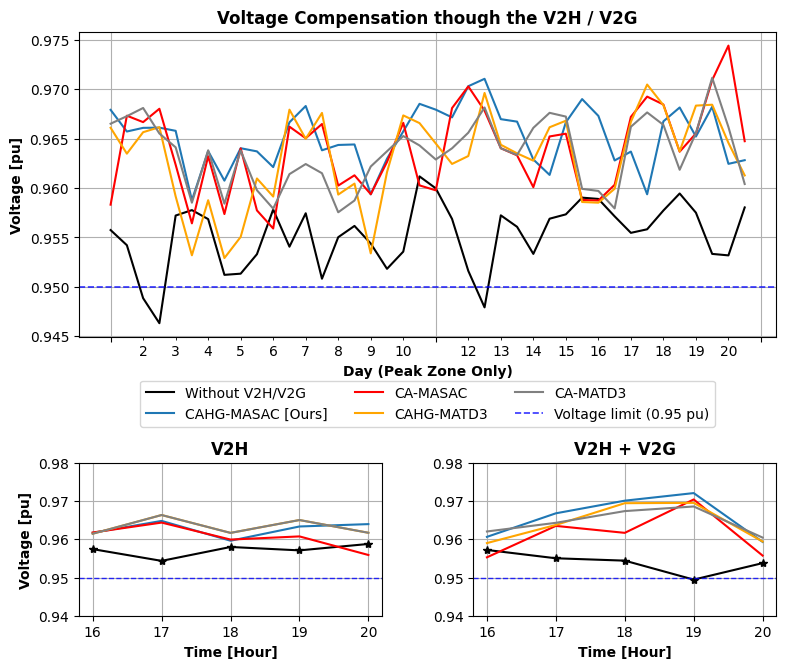

In [8]:
fig = plt.figure(figsize=(9, 8))
gs = GridSpec(2, 2, height_ratios=[2, 1], hspace=0.55)
V_REF = 0.95
vpu_def = pd.read_csv("./results/vpu_def.txt")
vpu_hsac_10 = pd.read_csv("./results/vpu_hsac.txt")
vpu_sac_10 = pd.read_csv("./results/vpu_sac.txt")
vpu_htd_10 = pd.read_csv("./results/vpu_htd.txt")
vpu_td_10 = pd.read_csv("./results/vpu_td.txt")

ax_top = fig.add_subplot(gs[0, :])
x_ticks = np.arange(0, 40, 2)
labels = np.arange(1, len(x_ticks)+1)

x = np.arange(40)
ax_top.plot(x, vpu_def[200:240], color='black', label='Without V2H/V2G')
ax_top.plot(x, vpu_hsac_10[200:240], label='CAHG-MASAC [Ours]')
ax_top.plot(x, vpu_sac_10[200:240], color='red', label='CA-MASAC')
ax_top.plot(x, vpu_htd_10[200:240], color='orange', label='CAHG-MATD3')
ax_top.plot(x, vpu_td_10[200:240], color='gray', label='CA-MATD3')
ax_top.axhline(
    y=V_REF,
    color='blue',
    linestyle='--',
    linewidth=1.2,
    alpha=0.8,
    label='Voltage limit (0.95 pu)'
)

ax_top.set_title("Voltage Compensation though the V2H / V2G", fontweight="bold")
ax_top.set_xlabel("Day (Peak Zone Only)", fontweight="bold")
ax_top.xaxis.set_major_locator(MultipleLocator(20))
ax_top.xaxis.set_minor_locator(MultipleLocator(20))
ax_top.set_xticks(x_ticks, minor=True)
ax_top.set_xticklabels(labels, minor=True)
ax_top.tick_params(axis='x', which='major', labelbottom=False)
ax_top.set_ylabel("Voltage [pu]", fontweight="bold")
ax_top.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True,
    fontsize=10
)

ax_top.grid(True)
axs = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
]

y_min, y_max = 0.940, 0.980
x_zoom = np.arange(16, 21)

axs[0].plot(x_zoom, vpu_def[420:425], color='black', marker='*')
axs[0].plot(x_zoom, vpu_hsac_10[420:425])
axs[0].plot(x_zoom, vpu_sac_10[420:425], color='red')
axs[0].plot(x_zoom, vpu_htd_10[420:425], color='orange')
axs[0].plot(x_zoom, vpu_htd_10[420:425], color='gray')
axs[0].set_title('V2H', fontsize=12, fontweight="bold")
axs[0].set_ylim(y_min, y_max)
axs[0].grid(True)


axs[1].plot(x_zoom, vpu_def[245+180:250+180], color='black', marker='*')
axs[1].plot(x_zoom, vpu_hsac_10[245+180:250+180])
axs[1].plot(x_zoom, vpu_sac_10[245+180:250+180], color='red')
axs[1].plot(x_zoom, vpu_htd_10[245+180:250+180], color='orange')
axs[1].plot(x_zoom, vpu_td_10[245+180:250+180], color='gray')
axs[1].set_title('V2H + V2G', fontsize=12, fontweight="bold")
axs[1].set_ylim(y_min, y_max)
axs[1].grid(True)
for ax in axs:
    ax.axhline(
        y=V_REF,
        color='blue',
        linestyle='--',
        linewidth=1.0,
        alpha=0.8
    )

for ax in axs:
    ax.set_xlabel('Time [Hour]', fontweight="bold")
axs[0].set_ylabel('Voltage [pu]', fontweight="bold")

plt.subplots_adjust(hspace=0.5, wspace=0.3, bottom=0.15)
fig.savefig(FIGURE_CSV_DIR / "Figure10_Voltage_Profiles.png", dpi=1200, bbox_inches="tight")
plt.show()

out_dir = FIGURE_CSV_DIR
pd.DataFrame({"Day": labels.repeat(2)[:40], "Without_V2H_V2G": vpu_def.iloc[200:240, 0].to_numpy(), "CAHG_MASAC": vpu_hsac_10.iloc[200:240, 0].to_numpy(), "CA_MASAC": vpu_sac_10.iloc[200:240, 0].to_numpy(), "CAHG_MATD3": vpu_htd_10.iloc[200:240, 0].to_numpy(), "CA_MATD3": vpu_td_10.iloc[200:240, 0].to_numpy()}).to_csv(out_dir / "Figure10_Top_Voltage.csv", index=False)
pd.DataFrame({"Time_Hour": x_zoom, "Without_V2H_V2G": vpu_def.iloc[420:425, 0].to_numpy(), "CAHG_MASAC": vpu_hsac_10.iloc[420:425, 0].to_numpy(), "CA_MASAC": vpu_sac_10.iloc[420:425, 0].to_numpy(), "CAHG_MATD3": vpu_htd_10.iloc[420:425, 0].to_numpy(), "CA_MATD3": vpu_htd_10.iloc[420:425, 0].to_numpy()}).to_csv(out_dir / "Figure10_Bottom_V2H.csv", index=False)
pd.DataFrame({"Time_Hour": x_zoom, "Without_V2H_V2G": vpu_def.iloc[425:430, 0].to_numpy(), "CAHG_MASAC": vpu_hsac_10.iloc[425:430, 0].to_numpy(), "CA_MASAC": vpu_sac_10.iloc[425:430, 0].to_numpy(), "CAHG_MATD3": vpu_htd_10.iloc[425:430, 0].to_numpy(), "CA_MATD3": vpu_td_10.iloc[425:430, 0].to_numpy()}).to_csv(out_dir / "Figure10_Bottom_V2H_V2G.csv", index=False)

# Figure 11. BCA Analysis

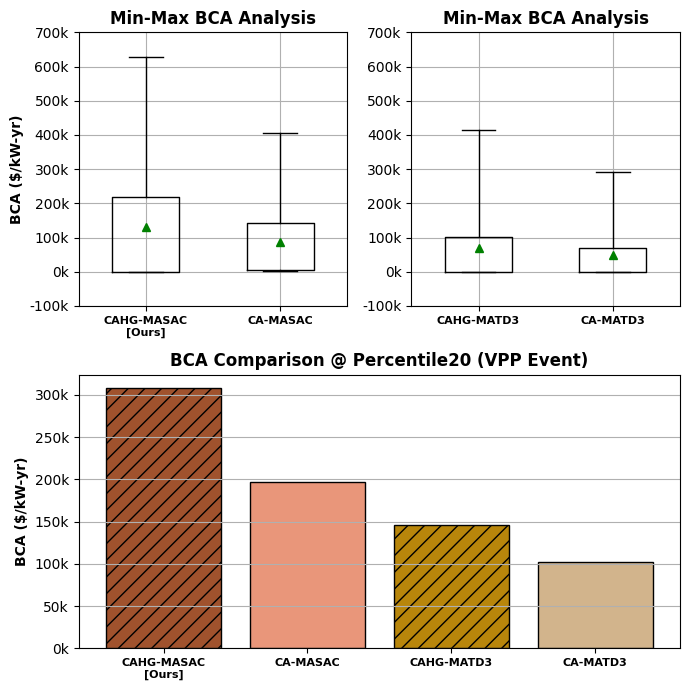

In [9]:
files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))

BCA_LOSS, BCA_DCF, BCA_MDC = 0.0728, 1.0, 28.0
P_RATED_KW, PEAK_HOURS = 7.0, 5

D = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
if "sweep_type" in D.columns: D = D[D["sweep_type"] != "scaling"].copy()
D = D[(D["condition"] == MAIN_CONDITION) & (D["phase"] == "eval")].copy()
D = D.drop_duplicates(["condition", "algorithm", "seed", "day_idx"], keep="last")
D["name"] = D["algorithm"].replace({"CAHG-MASAC": "CAHG-MASAC [Ours]"})
D["vpp_request"] = D["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

D["E_kWh"] = D["V2H_kWh"] + D["V2G_kWh"]
D["DF"] = D["E_kWh"] / (D["n_participants"].replace(0, np.nan) * P_RATED_KW * PEAK_HOURS)
D["BCA"] = D["E_kWh"] / (1 - BCA_LOSS) * BCA_DCF * D["DF"] * BCA_MDC

BCA_ALGOS = ["CAHG-MASAC [Ours]", "CA-MASAC", "CAHG-MATD3", "CA-MATD3"]
BCA_DAY = {n: D[D["name"] == n].groupby("day_idx")["BCA"].mean().dropna() for n in BCA_ALGOS}
BCA_REQUEST = {n: D[(D["name"] == n) & D["vpp_request"]].groupby("day_idx")["BCA"].mean().dropna() for n in BCA_ALGOS}

fig = plt.figure(figsize=(7, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

for k, pair in enumerate((BCA_ALGOS[:2], BCA_ALGOS[2:])):
    ax = fig.add_subplot(gs[0, k])
    ax.boxplot([BCA_DAY[n].to_numpy() for n in pair], whis=(0, 100), showmeans=True, widths=0.5,
               meanprops=dict(marker="^", markerfacecolor="green", markeredgecolor="green"),
               medianprops=dict(color="none"))
    ax.set_xticks([1, 2], [n.replace(" [Ours]", "\n[Ours]") for n in pair], fontsize=8, fontweight="bold")
    ax.set_title("Min-Max BCA Analysis", fontweight="bold")
    ax.set_ylabel("BCA ($/kW-yr)" if k == 0 else "", fontweight="bold")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    ax.grid(True)

ymax = max(BCA_DAY[n].max() for n in BCA_ALGOS)
upper = np.ceil(ymax / 100000) * 100000
lower = -100000

for ax in fig.axes:
    ax.set_ylim(lower, upper)
    ax.set_yticks(np.arange(lower, upper + 1, 100000))

ax = fig.add_subplot(gs[1, :])
p20 = [np.percentile(BCA_REQUEST[n], 20) for n in BCA_ALGOS]
bars = ax.bar(range(4), p20, color=["#a0522d", "#e9967a", "#b8860b", "#d2b48c"], edgecolor="black")

for i, bar in enumerate(bars):
    if i in (0, 2): bar.set_hatch("//")

ax.set_xticks(range(4), [n.replace(" [Ours]", "\n[Ours]") for n in BCA_ALGOS], fontsize=8, fontweight="bold")
ax.set_title("BCA Comparison @ Percentile20 (VPP Event)", fontweight="bold")
ax.set_ylabel("BCA ($/kW-yr)", fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.grid(True, axis="y")

fig.tight_layout()
fig.savefig(FIGURE_CSV_DIR / "Figure11_BCA.png", dpi=1200, bbox_inches="tight")
plt.show()

bca_box = pd.DataFrame(BCA_DAY)
bca_box.index.name = "day_idx"
bca_box.to_csv(FIGURE_CSV_DIR / "Figure11_BCA_Boxplot.csv", encoding="utf-8-sig")

bca_p20 = pd.DataFrame({
    "Algorithm": BCA_ALGOS,
    "BCA_P20": p20
})
bca_p20.to_csv(FIGURE_CSV_DIR / "Figure11_BCA_analysis.csv", index=False, encoding="utf-8-sig")

# Table 6, 7, 8, 9. Sensitive Studies

In [10]:
T95_WINDOW = 5
T95_THRESHOLD = 0.95
T95_SMOOTH_WINDOW = 10

files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
if not files: raise FileNotFoundError(f"No CSV files found in {RUN_DIR}")

S = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
S = S.drop_duplicates(["condition", "algorithm", "seed", "day_idx", "phase"], keep="last")
S = S[S["sweep_type"].isin(["w3", "participation", "rho", "tariff"])].copy()
S = S[(S["algorithm"] == "CAHG-MASAC") & (S["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"]))].copy()
S["day_idx"] = pd.to_numeric(S["day_idx"], errors="coerce")
S["reward"] = pd.to_numeric(S["reward"], errors="coerce")

def sustained_t95_event(rewards):
    y = pd.Series(np.asarray(rewards, dtype=float))
    if len(y) < T95_SMOOTH_WINDOW + T95_WINDOW - 1: return np.nan
    smooth = y.rolling(T95_SMOOTH_WINDOW, min_periods=T95_SMOOTH_WINDOW).mean().to_numpy()
    if not np.isfinite(smooth).any(): return np.nan
    target = T95_THRESHOLD * np.nanmax(smooth)
    for start in range(len(smooth) - T95_WINDOW + 1):
        segment = smooth[start:start + T95_WINDOW]
        if np.isfinite(segment).all() and np.all(segment >= target): return float(start + 1)
    return np.nan

def study_table(study, col, values, labels, title):
    data = S[(S["sweep_type"] == study) & (S["phase"] == "train")]
    result = {}
    for value, label in zip(values, labels):
        q = data[np.isclose(pd.to_numeric(data[col], errors="coerce"), value)] if col != "tariff" else data[data[col] == value]
        if q.empty: continue
        daily = q.groupby("day_idx")["reward"].mean().sort_index()
        last30_reward = daily.tail(30).mean()
        per_seed_t95 = []
        for seed, group in q.groupby("seed"):
            seed_daily = group.groupby("day_idx")["reward"].mean().sort_index()
            per_seed_t95.append(sustained_t95_event(seed_daily.to_numpy()))
        valid = np.asarray(per_seed_t95, dtype=float)
        valid = valid[np.isfinite(valid)]
        result[label] = {"Training Reward (Last 30)": round(last30_reward, 3), "Sustained T95 median (per seeds)": float(np.median(valid)) if len(valid) else np.nan}
    table = pd.DataFrame(result)
    table.columns.name = title
    display(table)
    return table

T6 = study_table("w3", "vdev_weight", [0.2, 0.5, 1.0, 1.5, 2.0], ["0.2", "0.5", "1", "1.5", "2"], "Voltage deviation weighting [w3]")
T7 = study_table("participation", "participation_rate", [1.0, 0.8, 0.5, 0.3], ["100%", "80%", "50%", "30%"], "V2G eligible rate")
T8 = study_table("rho", "rho", [0.0, 0.2, 0.4, 0.8, 1.0], ["0.0", "0.2", "0.4", "0.8", "1.0"], "Buffer mixing ratio [ρ]")
T9 = study_table("tariff", "tariff", ["CA", "TX"], ["TOU [California]", "Flat [Texas]"], "Electricity rate")

FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
T6.to_csv(FIGURE_CSV_DIR / "Table6_Voltage_Weight.csv", encoding="utf-8-sig")
T7.to_csv(FIGURE_CSV_DIR / "Table7_Participation.csv", encoding="utf-8-sig")
T8.to_csv(FIGURE_CSV_DIR / "Table8_Buffer_Mixing.csv", encoding="utf-8-sig")
T9.to_csv(FIGURE_CSV_DIR / "Table9_Electricity_Rate.csv", encoding="utf-8-sig")

Voltage deviation weighting [w3],0.2,0.5,1,1.5,2
Training Reward (Last 30),3.077,3.06,2.958,2.888,2.913
Sustained T95 median (per seeds),65.000,63.00,65.000,64.000,64.000


V2G eligible rate,100%,80%,50%,30%
Training Reward (Last 30),3.636,3.077,2.051,1.262
Sustained T95 median (per seeds),66.000,65.000,63.000,64.000


Buffer mixing ratio [ρ],0.0,0.2,0.4,0.8,1.0
Training Reward (Last 30),2.225,3.012,3.077,2.995,2.748
Sustained T95 median (per seeds),66.000,64.000,65.000,63.500,71.000


Electricity rate,TOU [California],Flat [Texas]
Training Reward (Last 30),3.077,3.731
Sustained T95 median (per seeds),65.000,63.000


# Table 10. Battery Degration Impact Analysis

In [11]:
DEG_OFF, DEG_ON = 0.0, 1.0
DEG_ALGO = "hsac"
N_EV = 400

files = sorted(Path(RUN_DIR).glob("seed*/all_reward_weight_sensitivity_seed_summary*.csv"))
if not files: raise FileNotFoundError(f"No degradation CSV files found in {RUN_DIR}")

B = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
B = B[(B["sweep_type"] == "degradation") & (B["algo"] == DEG_ALGO)].copy()
B = B.drop_duplicates(["condition", "seed"], keep="last")

daily_files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
D = pd.concat([pd.read_csv(f) for f in daily_files], ignore_index=True)
D = D[
    (D["sweep_type"] == "degradation") &
    (D["algo"] == DEG_ALGO) &
    (D["phase"] == "train")
].copy()

D = D.drop_duplicates(["condition", "seed", "day_idx"], keep="last")
D["vpp_request"] = D["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

days = (
    D.groupby(["condition", "seed", "vpp_request"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={False: "V2H_days", True: "V2G_days"})
)

B = B.join(days, on=["condition", "seed"])

off = B[np.isclose(B["deg_weight"], DEG_OFF)].set_index("seed").sort_index()
on = B[np.isclose(B["deg_weight"], DEG_ON)].set_index("seed").sort_index()

seeds = off.index.intersection(on.index)
off, on = off.loc[seeds], on.loc[seeds]
if len(seeds) < 2: raise ValueError("At least two paired seeds are required.")

METRICS = [
    ("V2H (mean - kWh/EV/day)", "V2H_kWh", 3),
    ("V2G (mean - kWh/EV/day)", "V2G_kWh", 3),
    ("Final SOC (%)", "final_SOC", 2)
]

rows = []
for label, col, digits in METRICS:
    a, b = off[col].astype(float), on[col].astype(float)

    if col == "V2H_kWh":
        a = a / (N_EV * off["V2H_days"].replace(0, np.nan))
        b = b / (N_EV * on["V2H_days"].replace(0, np.nan))
    elif col == "V2G_kWh":
        a = a / (N_EV * off["V2G_days"].replace(0, np.nan))
        b = b / (N_EV * on["V2G_days"].replace(0, np.nan))
    else:
        a, b = a * 100, b * 100

    change = 100 * (b.mean() - a.mean()) / a.mean() if a.mean() != 0 else np.nan

    rows.append({
        "Metric": label,
        "Degradation Off (λ=0)": f"{a.mean():,.{digits}f} ± {a.std(ddof=1):,.{digits}f}",
        "Degradation On (λ=1)": f"{b.mean():,.{digits}f} ± {b.std(ddof=1):,.{digits}f}",
        "Change (%)": f"{change:+.1f}%"
    })

T10 = pd.DataFrame(rows)
display(T10.style.hide(axis="index"))

FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
T10.to_csv(FIGURE_CSV_DIR / "Table10_Degradation_Comparison.csv", index=False, encoding="utf-8-sig")

Metric,Degradation Off (λ=0),Degradation On (λ=1),Change (%)
V2H (mean - kWh/EV/day),12.554 ± 0.422,12.521 ± 0.261,-0.3%
V2G (mean - kWh/EV/day),19.393 ± 0.671,19.188 ± 0.364,-1.1%
Final SOC (%),24.55 ± 1.45,27.04 ± 4.36,+10.2%


# Figure 12. OpenDSS & GridLAB-D

OpenDSS vs GridLAB-D voltage comparison
Bus/Phase         : 63.1 (A)
MAE               : 0.006193 p.u.


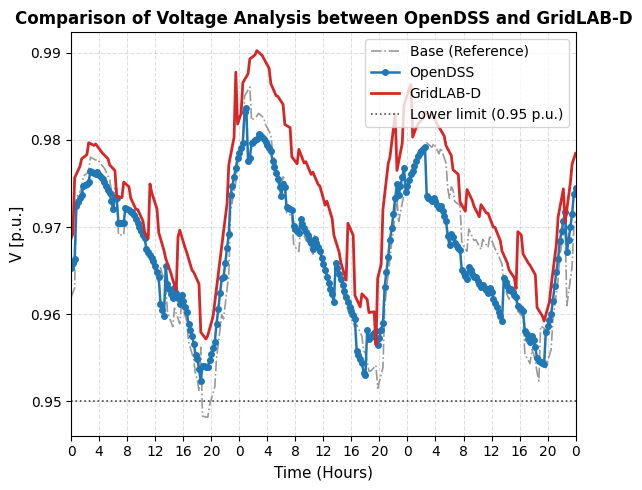

In [12]:
%run "OpenDSS_GridLabD.py"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("OpenDSS vs GridLAB-D voltage comparison")
print("=" * 70)
print("Bus/Phase         : 63.1 (A)")
print(f"MAE               : {mae:.6f} p.u.")

pd.DataFrame({"Timestamp": comparison_df["Timestamp"], "Time_hour": time_hours, "OpenDSS_S3_Vpu": comparison_df["OpenDSS_S3_Vpu"]}).to_csv(FIGURE_CSV_DIR / "Figure12_OpenDSS_withoutV2G.csv", index=False)
pd.DataFrame({"Timestamp": comparison_df["Timestamp"], "Time_hour": time_hours, "OpenDSS_S4_Vpu": comparison_df["OpenDSS_S4_Vpu"]}).to_csv(FIGURE_CSV_DIR / "Figure12_OpenDSS_withV2G.csv", index=False)
pd.DataFrame({"Timestamp": comparison_df["Timestamp"], "Time_hour": time_hours, "GridLABD_S4_Vpu": comparison_df["GridLABD_S4_Vpu"]}).to_csv(FIGURE_CSV_DIR / "Figure12_GridLABD_withV2G.csv", index=False)
comparison_df.assign(Time_hour=time_hours)[["Timestamp", "Time_hour", "OpenDSS_S3_Vpu", "OpenDSS_S4_Vpu", "GridLABD_S4_Vpu", "Absolute_Error_pu"]].to_csv(FIGURE_CSV_DIR / "All_Series_and_MAE.csv", index=False)

TICK_INTERVAL = 4
time_array = np.asarray(time_hours, dtype=float)
time_elapsed = time_array - time_array[0]
mask = np.isfinite(time_elapsed) & (time_elapsed >= 0) & (time_elapsed <= 72)
plot_time = time_elapsed[mask]
plot_df = comparison_df.iloc[np.flatnonzero(mask)]
ticks = np.arange(0, 73, TICK_INTERVAL)
F12 = pd.DataFrame({
    "Time_hour": plot_time,
    "Base_Reference_Vpu": plot_df["OpenDSS_S3_Vpu"].to_numpy(),
    "OpenDSS_Vpu": plot_df["OpenDSS_S4_Vpu"].to_numpy(),
    "GridLABD_Vpu": plot_df["GridLABD_S4_Vpu"].to_numpy(),
    "Lower_Limit_Vpu": 0.95
})
F12.to_csv(FIGURE_CSV_DIR / "Figure12_Plot_Data.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(6, 5))
plt.plot(plot_time, plot_df["OpenDSS_S3_Vpu"], label="Base (Reference)", color="gray", linestyle="dashdot", linewidth=1.2, alpha=0.8)
plt.plot(plot_time, plot_df["OpenDSS_S4_Vpu"], label="OpenDSS", color="#1f77b4", linestyle="-", linewidth=1.8, marker="o", markersize=4)
plt.plot(plot_time, plot_df["GridLABD_S4_Vpu"], label="GridLAB-D", color="#d62728", linestyle="-", linewidth=2)
plt.axhline(0.95, color="black", linestyle=":", linewidth=1.2, alpha=0.7, label="Lower limit (0.95 p.u.)")
plt.title("Comparison of Voltage Analysis between OpenDSS and GridLAB-D", fontsize=12, fontweight="bold")
plt.xlabel("Time (Hours)", fontsize=11)
plt.ylabel("V [p.u.]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(ticks, [str(int(t % 24)) for t in ticks], fontsize=10)
plt.xlim(0, 72)
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.gcf().savefig(FIGURE_CSV_DIR / "Figure12_OpenDSS_GridLABD.png", dpi=1200, bbox_inches="tight")
plt.show()

# Table 11. Computation time analysis

In [13]:
files = sorted(Path(RUN_DIR).glob("seed*/all_timing*.csv"))
if not files:
    raise FileNotFoundError("Timing CSV files not found.")

T = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
T = T[T["sweep_type"] == "scaling"].copy()


rows = []

for (condition, algo, seed, n_evs), g in T.groupby(
    ["condition", "algo", "seed", "n_evs"]
):
    g = g.sort_values("day_idx")
    episodes = g[g["phase"].isin(["warmup", "train"])].sort_values("day_idx")
    setup = g.loc[g["phase"] == "setup", "wall_total_s"].sum()

    row = {"Number of EVs": int(n_evs), "algorithm": algo, "seed": seed}

    for n in [100, 200, 300]:
        if len(episodes) >= n:
            part = episodes.head(n)
            total = setup + part["wall_total_s"].sum()
            row[f"{n} episodes"] = total
        else:
            row[f"{n} episodes"] = np.nan

    rows.append(row)

R = pd.DataFrame(rows)

def mean_sd(x):
    x = x.dropna()
    if x.empty:
        return "N/A"
    return f"{x.mean():,.2f} ± {x.std(ddof=1):,.2f}" if len(x) > 1 else f"{x.mean():,.2f}"

metrics = [
    "100 episodes",
    "200 episodes",
    "300 episodes"
]

T11 = R.groupby("Number of EVs")[metrics].agg(mean_sd).T

T11.index = [
    "100 episodes (mean ± SD)",
    "200 episodes (mean ± SD)",
    "300 episodes (mean ± SD)"
]
T11.columns.name = "Number of EVs"
display(T11)

out = FIGURE_CSV_DIR


blocks = [T11.astype(str)]
seed_metrics = [
    "100 episodes",
    "200 episodes",
    "300 episodes"
]

for seed in sorted(R["seed"].unique()):
    S = R[R["seed"] == seed]

    seed_table = S.groupby("Number of EVs")[seed_metrics].mean().T
    seed_table.index = [
        "100 episodes",
        "200 episodes",
        "300 episodes"
    ]

    seed_table = seed_table.reindex(columns=T11.columns)
    seed_table = seed_table.apply(lambda col: col.map(
        lambda x: f"{x:.2f}" if pd.notna(x) else ""
    ))

    title = pd.DataFrame(
        [[""] * len(T11.columns)],
        index=[f"Seed {seed}"],
        columns=T11.columns
    )

    blocks.extend([title, seed_table])

T11_all = pd.concat(blocks)
T11_all.index.name = "Number of EVs"

T11_all.to_csv(out / "Table11_timing_all_seeds.csv", encoding="utf-8-sig")

Number of EVs,100,200,300,400,500
100 episodes (mean ± SD),14.52 ± 0.10,17.15 ± 0.07,19.77 ± 0.04,22.43 ± 0.08,25.09 ± 0.09
200 episodes (mean ± SD),22.98 ± 0.12,28.54 ± 0.10,34.04 ± 0.08,39.75 ± 0.15,45.29 ± 0.16
300 episodes (mean ± SD),31.38 ± 0.15,39.91 ± 0.17,48.26 ± 0.12,56.81 ± 0.21,65.20 ± 0.22
